# 01 - Exploratory Data Analysis

Looks at the three raw ingredients before any modeling: the 132 selected stations, the historic flood warnings, and the assembled training table. See `PLAN.md` for how each of these was built (spike task, station selection, spatial join to warnings).


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (9, 4)


## Stations

In [2]:
stations = pd.read_csv("../data/stations.csv")
print(f"{len(stations)} stations")
stations[["station_id", "label", "catchment_name", "parameter", "live_rainfall_distance_km"]].head()


132 stations


,station_id,label,catchment_name,parameter,live_rainfall_distance_km
0,3115TH,Knowle Green,Ash (Herts),level,3.815644
1,5541TH,Hornchurch_Bretons Farm,Beam and Ingrebourne,level,1.878951
2,5546TH,Harold Park,Beam and Ingrebourne,level,0.649932
3,5522TH,Romford,Beam and Ingrebourne,level,3.171183
4,5550TH,Gaynes Park,Beam and Ingrebourne,level,5.199838


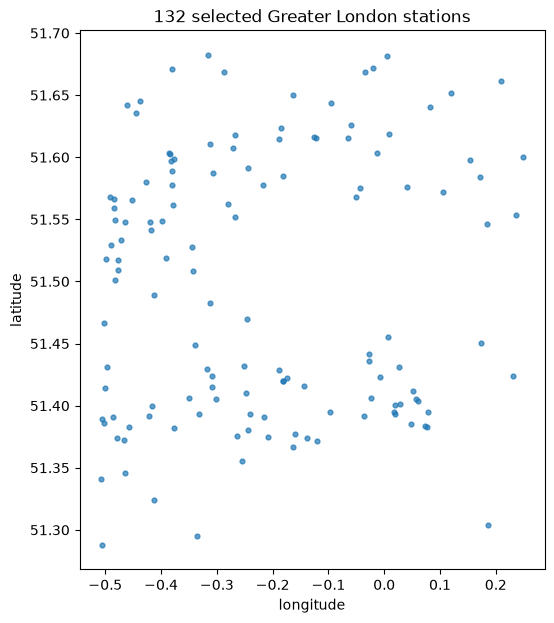

In [3]:
fig, ax = plt.subplots(figsize=(6, 7))
ax.scatter(stations["long"], stations["lat"], s=12, alpha=0.7)
ax.set_title(f"{len(stations)} selected Greater London stations")
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
plt.show()


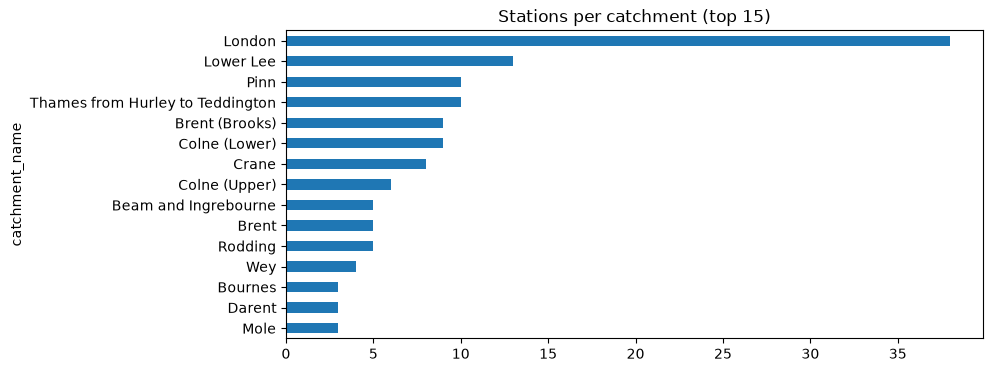

In [4]:
stations["catchment_name"].value_counts().head(15).plot(kind="barh")
plt.title("Stations per catchment (top 15)")
plt.gca().invert_yaxis()
plt.show()


`parameter` shows most stations report `level`; a handful (3) only have `flow` measures instead -- both were treated as the primary river signal at that station (see `src/download_readings.py`).


In [5]:
stations["parameter"].value_counts()


parameter
level    129
flow       3
Name: count, dtype: int64

## Historic flood warnings, matched to stations

In [6]:
warnings = pd.read_csv("../data/warnings_matched.csv", parse_dates=["date_time"])
print(f"{len(warnings)} warning-type events matched to a station within 5km")
warnings["warning_type"].value_counts()


2808 warning-type events matched to a station within 5km


warning_type
Flood Alert             2324
Flood Warning            242
Update Flood Alert       205
Update Flood Warning      26
Severe Flood Warning      11
Name: count, dtype: int64

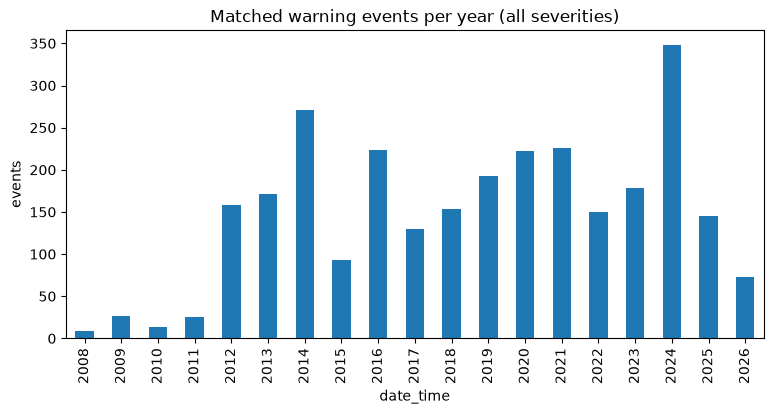

In [7]:
by_year = warnings.set_index("date_time").resample("YE").size()
by_year.index = by_year.index.year
by_year.plot(kind="bar")
plt.title("Matched warning events per year (all severities)")
plt.ylabel("events")
plt.show()


Events are lumpy year to year -- this is exactly why the train/val/test split (`src/train.py`) was chosen by checking positive-episode counts per candidate window rather than picking round fractions of rows. 2024 alone accounts for a large share of the total.


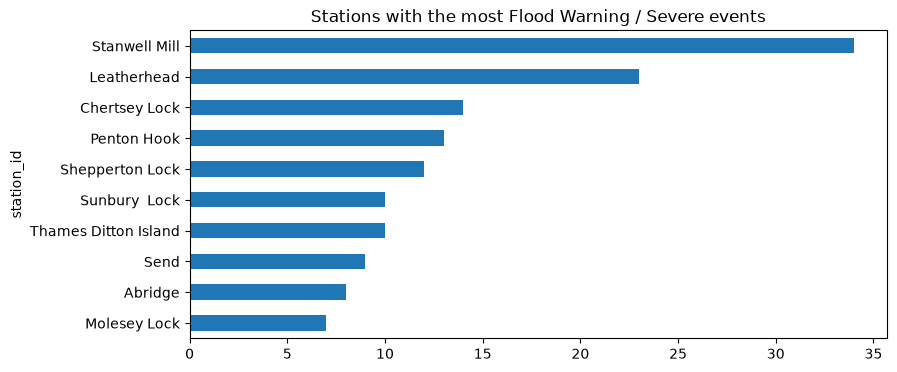

In [8]:
warning_only = warnings[warnings["warning_type"].isin(["Flood Warning", "Severe Flood Warning"])]
top_stations = warning_only["station_id"].value_counts().head(10)
top_stations = top_stations.rename(stations.set_index("station_id")["label"])
top_stations.plot(kind="barh")
plt.title("Stations with the most Flood Warning / Severe events")
plt.gca().invert_yaxis()
plt.show()


## The assembled training table

In [9]:
table = pd.read_parquet("../data/processed/training_table.parquet")
print(f"{len(table):,} rows, {table['station_id'].nunique()} stations")
print(f"positive rate: {table['label'].mean():.4%}")
table.head()


18,209,294 rows, 132 stations
positive rate: 0.0274%


,date_time,value,rate_of_rise_1h,rate_of_rise_6h,rate_of_rise_12h,rainfall_6h,rainfall_24h,rainfall_72h,rainfall_7d,rainfall_peak_intensity,level_vs_24h_peak,baseline,level_minus_baseline,season_sin,season_cos,label,station_id,parameter
0,2010-01-02 00:00:00,0.392,0.0,-0.000167,-0.000167,0.0,0.0,0.0,0.0,0.0,-0.004,0.394,-0.002,0.034398,0.999408,0,3115TH,level
1,2010-01-02 01:00:00,0.392,0.0,-0.000167,-0.000167,0.0,0.0,0.0,0.0,0.0,-0.004,0.394,-0.002,0.034398,0.999408,0,3115TH,level
2,2010-01-02 02:00:00,0.392,0.0,0.000000,-0.000167,0.0,0.0,0.0,0.0,0.0,-0.004,0.394,-0.002,0.034398,0.999408,0,3115TH,level
3,2010-01-02 03:00:00,0.392,0.0,0.000000,-0.000083,0.0,0.0,0.0,0.0,0.0,-0.004,0.394,-0.002,0.034398,0.999408,0,3115TH,level
4,2010-01-02 04:00:00,0.392,0.0,-0.000167,-0.000083,0.0,0.0,0.0,0.0,0.0,-0.003,0.394,-0.002,0.034398,0.999408,0,3115TH,level


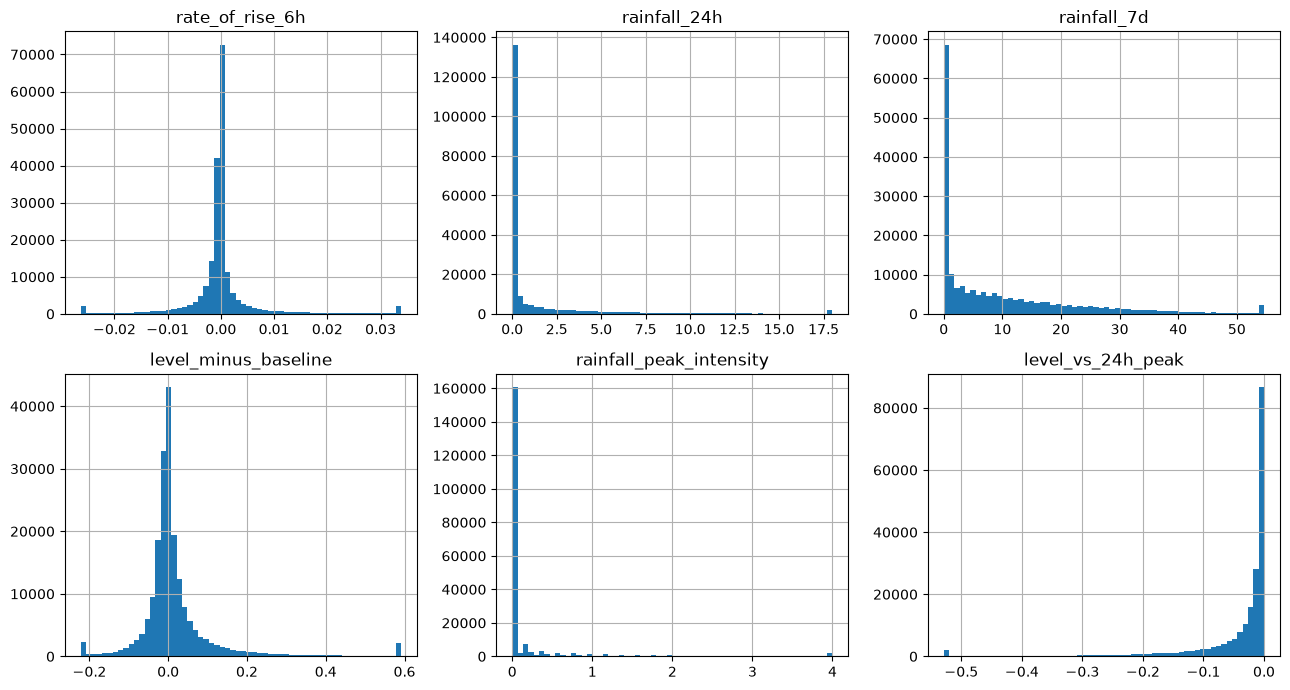

In [10]:
# 18M rows is too many points to scatter -- sample for the feature-distribution plots
sample = table.sample(200_000, random_state=0)

fig, axes = plt.subplots(2, 3, figsize=(13, 7))
feature_cols = ["rate_of_rise_6h", "rainfall_24h", "rainfall_7d", "level_minus_baseline", "rainfall_peak_intensity", "level_vs_24h_peak"]
for ax, col in zip(axes.flat, feature_cols):
    sample[col].clip(sample[col].quantile(0.01), sample[col].quantile(0.99)).hist(bins=60, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()


Feature distributions are clipped to the 1st-99th percentile for the histograms above -- raw rate-of-rise and rainfall features have long tails (a handful of genuine flood-level spikes), which would otherwise flatten everything else in the plot.


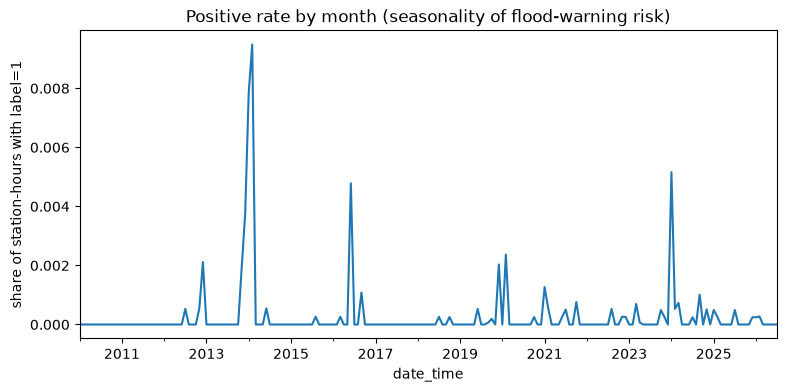

In [11]:
monthly_rate = table.set_index("date_time")["label"].resample("ME").mean()
monthly_rate.plot()
plt.title("Positive rate by month (seasonality of flood-warning risk)")
plt.ylabel("share of station-hours with label=1")
plt.show()


Positive rate spikes in wet-season months, consistent with the `season_sin`/`season_cos` features carrying real signal (confirmed later in the SHAP summary in `03_model_development.ipynb`).

Class imbalance, for scale:


In [12]:
counts = table["label"].value_counts()
print(counts)
print(f"imbalance ratio: 1 positive per {counts[0] / counts[1]:.0f} negative rows")


label
0    18204299
1        4995
Name: count, dtype: int64
imbalance ratio: 1 positive per 3645 negative rows
